# RUL Prediction — All Regression Models
### NASA IMS Bearing Dataset
Loads `rul_features_dataset.csv` produced by the Pipeline notebook.
Trains 9 models, evaluates on the same 80/20 split, produces final R² comparison.

## Step 1: Imports & Setup

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── Regressors ────────────────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.svm import SVR

try:
    from xgboost import XGBRegressor
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'xgboost', '-q'])
    from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("All imports OK")


TensorFlow: 2.21.0
All imports OK


## Step 2: Load Dataset
The CSV was saved by the **Pipeline notebook** (`RUL_Pipeline_DataPrep.ipynb`).

In [69]:
df = pd.read_csv("rul_features_final_dataset.csv")

print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
print("\nFirst 5 rows:")
df.head()


Dataset shape: (402, 35)
Columns: ['RMS', 'Mean', 'Std', 'Variance', 'Skewness', 'Kurtosis', 'Peak', 'Peak2Peak', 'CrestFactor', 'MAV', 'ShapeFactor', 'ClearanceFactor', 'SpectralEntropy', 'SpectralKurtosis', 'SpectralSkewness', 'PeakFreq', 'SpectralRMS', 'SpectralCentroid', 'SpectralEnergy', 'FreqVariance', 'BandPower1X', 'BandPower2X', 'WaveletEnergy', 'WaveletEntropy', 'WaveletRMS', 'WaveletKurtosis', 'WaveletVariance', 'time', 'HI', 'HI_top', 'Q_stat', 'fault_label', 'fault_type', 'confidence', 'RUL_true']

First 5 rows:


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,WaveletKurtosis,WaveletVariance,time,HI,HI_top,Q_stat,fault_label,fault_type,confidence,RUL_true
0,0.076604,-0.004030,0.076497,0.005852,0.051467,0.733794,0.608,1.184,7.936974,0.060066,...,1.536056,0.001468,2.5,0.001364,0.031729,0.573472,0,Outer Race,0.479897,1002.5
1,0.078190,-0.002040,0.078163,0.006110,0.038836,0.629359,0.608,1.184,7.775928,0.061425,...,1.400458,0.001531,5.0,0.001364,0.031729,0.212954,0,Outer Race,0.503494,1000.0
2,0.077893,-0.001867,0.077871,0.006064,0.044530,0.446463,0.439,0.847,5.635931,0.061364,...,1.149032,0.001511,7.5,0.001364,0.031729,0.162794,0,Outer Race,0.577414,997.5
3,0.077839,-0.001838,0.077817,0.006056,0.031762,0.466530,0.474,0.913,6.089490,0.061285,...,1.181460,0.001503,10.0,0.001364,0.031729,0.123082,0,Outer Race,0.501006,995.0
4,0.078591,-0.001731,0.078572,0.006174,0.025385,0.512199,0.474,0.913,6.031211,0.061795,...,1.290564,0.001539,12.5,0.001364,0.031729,0.263287,0,Outer Race,0.436709,992.5


In [70]:
# ── Extract arrays ───────────────────────────────────────────────────────────
time_final = df["time"].values
RUL_true   = df["RUL_true"].values
HI_top     = df["HI_top"].values

# Feature columns (exclude metadata)
meta_cols = ['time', 'HI', 'HI_top', 'Q_stat', 'fault_label', 'fault_type', 'confidence', 'RUL_true']
feat_cols = [c for c in df.columns if c not in meta_cols]

X_all = df[feat_cols].values    

try:
    top_df = pd.read_csv("rul_top_features_dataset.csv")
    top_feat_cols = [c for c in top_df.columns if c not in ["time","HI_top","RUL_true"]]
    X_top = top_df[top_feat_cols].values
    print("Top features loaded:", top_feat_cols)
except FileNotFoundError:
    # fallback: use first 5 columns of X_all
    top_feat_cols = feat_cols[:5]
    X_top = X_all[:, :5]
    print("Warning: rul_top_features_dataset.csv not found, using first 5 features")

print(f"\nX_all shape  : {X_all.shape}")
print(f"X_top shape  : {X_top.shape}")
print(f"RUL range    : 0 – {RUL_true.max():.1f}s")
print(f"Total windows: {len(df)}")


Top features loaded: ['BandPower1X', 'SpectralEntropy', 'SpectralCentroid', 'ShapeFactor', 'WaveletEntropy']

X_all shape  : (402, 27)
X_top shape  : (402, 5)
RUL range    : 0 – 1002.5s
Total windows: 402


## Step 3: Quick EDA on the Dataset

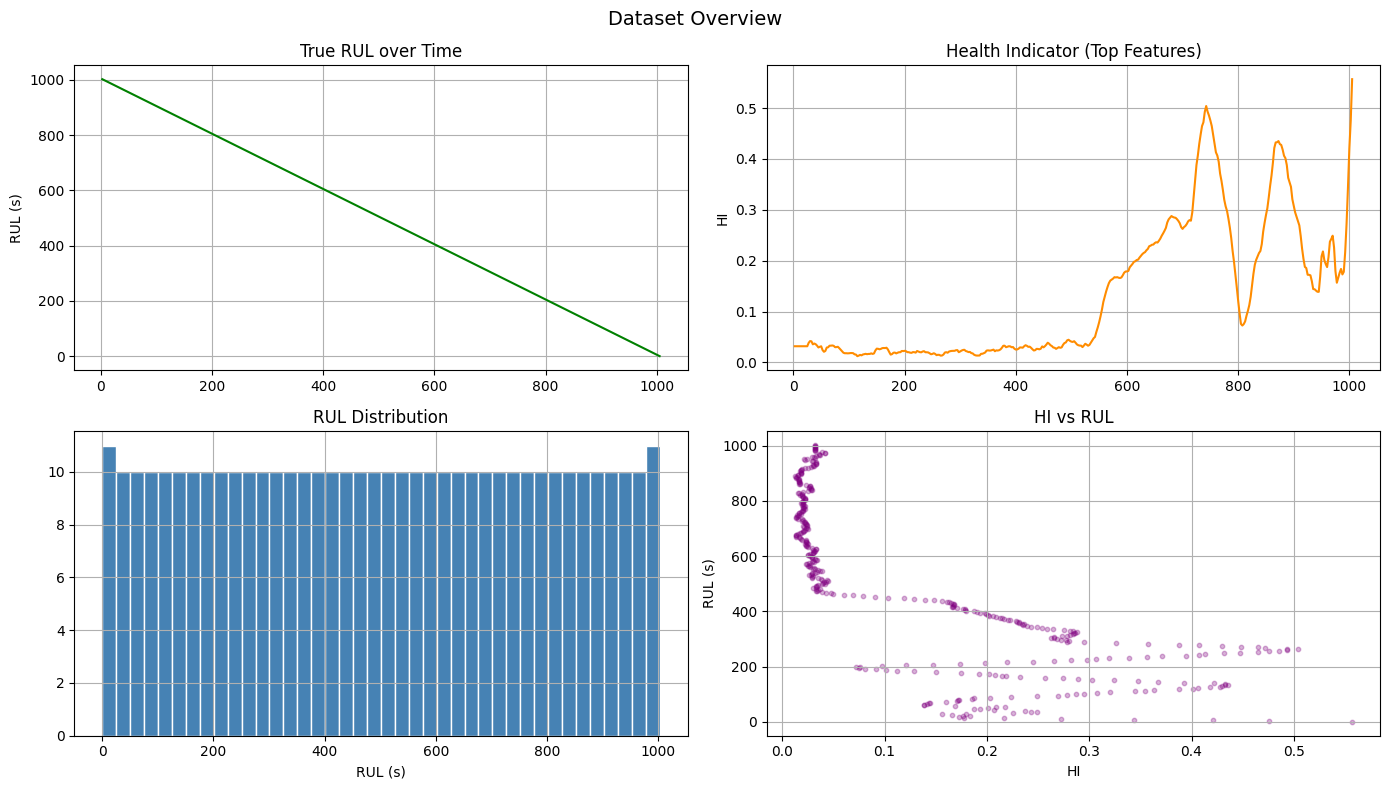

In [71]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0,0].plot(time_final, RUL_true, color='green')
axes[0,0].set_title("True RUL over Time"); axes[0,0].set_ylabel("RUL (s)"); axes[0,0].grid(True)

axes[0,1].plot(time_final, HI_top, color='darkorange')
axes[0,1].set_title("Health Indicator (Top Features)"); axes[0,1].set_ylabel("HI"); axes[0,1].grid(True)

axes[1,0].hist(RUL_true, bins=40, color='steelblue', edgecolor='white')
axes[1,0].set_title("RUL Distribution"); axes[1,0].set_xlabel("RUL (s)"); axes[1,0].grid(True)

axes[1,1].scatter(HI_top, RUL_true, alpha=0.3, s=10, color='purple')
axes[1,1].set_title("HI vs RUL"); axes[1,1].set_xlabel("HI"); axes[1,1].set_ylabel("RUL (s)"); axes[1,1].grid(True)

plt.suptitle("Dataset Overview", fontsize=14)
plt.tight_layout(); plt.show()


## Step 4: Shared Train/Test Split
All models use the **same 80/20 split** for fair comparison.

In [72]:
RANDOM_STATE = 42
TEST_SIZE    = 0.2

# Full features split
Xtr_full, Xte_full, ytr, yte = train_test_split(
    X_all, RUL_true, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Top features split (same indices via same seed)
Xtr_top, Xte_top, _, _ = train_test_split(
    X_top, RUL_true, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# PCA features (95% variance on full features)
pca = PCA(n_components=8, random_state=RANDOM_STATE)

X_pca_all = pca.fit_transform(X_all)
print(f"PCA kept {pca.n_components_} components ({pca.explained_variance_ratio_.sum()*100:.1f}% variance)")

Xtr_pca, Xte_pca, _, _ = train_test_split(
    X_pca_all, RUL_true, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Train size: {len(ytr)} | Test size: {len(yte)}")


PCA kept 8 components (100.0% variance)
Train size: 321 | Test size: 81


In [73]:
# ── Evaluation helper ────────────────────────────────────────────────────────
results = []   # accumulates (model_name, mae, rmse, r2)

def evaluate(name, y_true, y_pred, verbose=True):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    results.append({"Model": name, "MAE (s)": round(mae,2),
                    "RMSE (s)": round(rmse,2), "R²": round(r2,4)})
    if verbose:
        print(f"  {name:<30} MAE={mae:8.2f}s  RMSE={rmse:8.2f}s  R²={r2:.4f}")
    return mae, rmse, r2

def scatter_plot(name, y_true, y_pred, color='steelblue'):
    plt.figure(figsize=(6, 5))
    plt.scatter(y_true, y_pred, alpha=0.4, s=12, color=color)
    mn, mx = y_true.min(), y_true.max()
    plt.plot([mn, mx], [mn, mx], 'r--', label='Perfect')
    r2 = r2_score(y_true, y_pred)
    plt.title(f"{name}\nR²={r2:.4f}")
    plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

print("Helpers ready. Starting model training...")


Helpers ready. Starting model training...


## Model 1 — PCA + Random Forest (Baseline)

Original baseline model. PCA components fed into an RF with 100 trees.

  PCA + Random Forest            MAE=   33.42s  RMSE=   49.12s  R²=0.9749


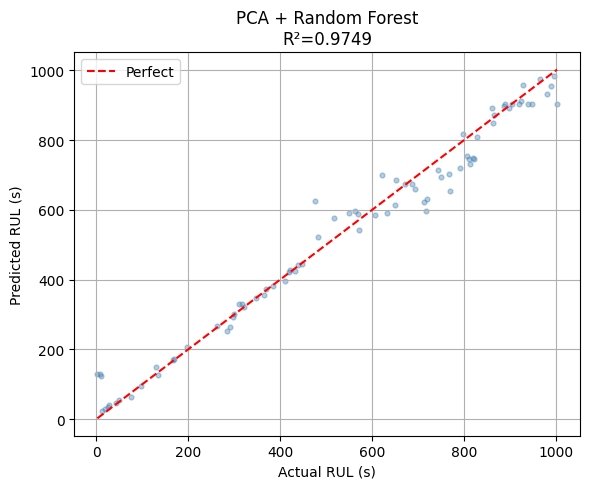

In [74]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=RANDOM_STATE)
rf.fit(Xtr_pca, ytr)
pred_rf = rf.predict(Xte_pca)

evaluate("PCA + Random Forest", yte, pred_rf)
scatter_plot("PCA + Random Forest", yte, pred_rf, color='steelblue')


## Model 2 — Kernel PCA + Random Forest

RBF Kernel PCA captures nonlinear manifold, then RF regresses on latent codes.

  KPCA + Random Forest           MAE=  213.31s  RMSE=  257.52s  R²=0.3108


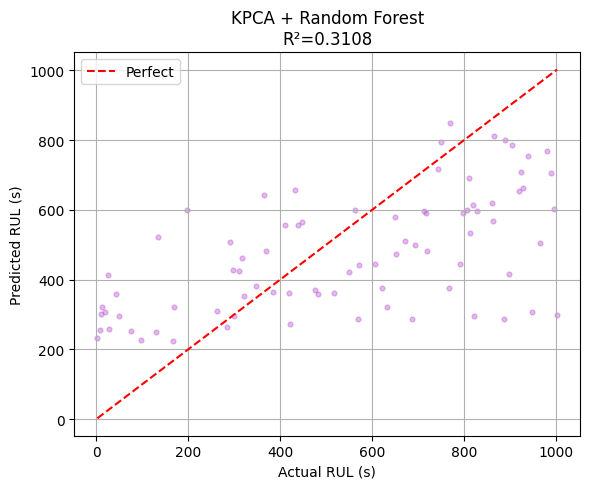

In [75]:
from sklearn.decomposition import KernelPCA

kpca = KernelPCA(n_components=6, kernel='rbf', gamma=0.1)
X_kpca = kpca.fit_transform(X_all)

Xtr_kpca, Xte_kpca, _, _ = train_test_split(
    X_kpca, RUL_true, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

rf_kpca = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=RANDOM_STATE)
rf_kpca.fit(Xtr_kpca, ytr)
pred_kpca = rf_kpca.predict(Xte_kpca)

evaluate("KPCA + Random Forest", yte, pred_kpca)
scatter_plot("KPCA + Random Forest", yte, pred_kpca, color='mediumorchid')


## Model 3 — Autoencoder + Random Forest

Deep autoencoder (64→32→**8**→32→64) compresses 27 features into an 8-dim latent space. RF regresses on latent codes. Reconstruction error also plotted as a degradation indicator.

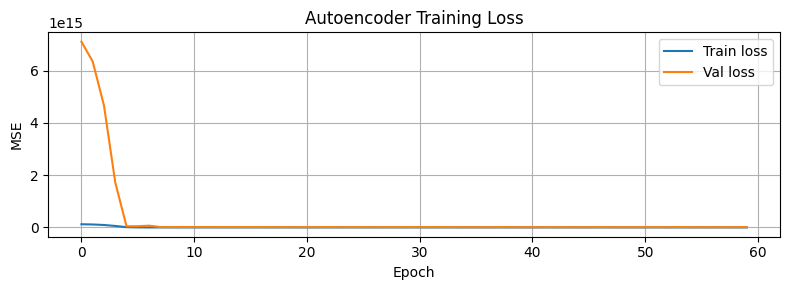

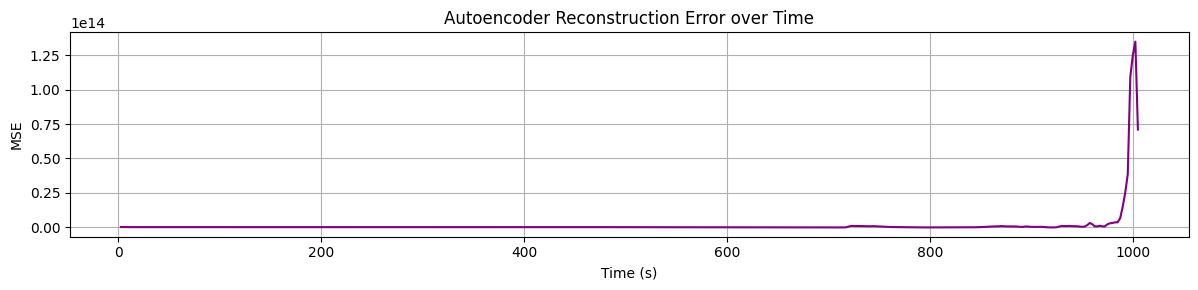

In [76]:
LATENT_DIM = 8
input_dim  = X_all.shape[1]

inp    = keras.Input(shape=(input_dim,))
enc    = layers.Dense(64, activation='relu')(inp)
enc    = layers.Dense(32, activation='relu')(enc)
latent = layers.Dense(LATENT_DIM, activation='relu', name='latent')(enc)
dec    = layers.Dense(32, activation='relu')(latent)
dec    = layers.Dense(64, activation='relu')(dec)
out    = layers.Dense(input_dim, activation='linear')(dec)

autoencoder = keras.Model(inp, out, name='autoencoder')
encoder     = keras.Model(inp, latent, name='encoder')
autoencoder.compile(optimizer='adam', loss='mse')

history_ae = autoencoder.fit(
    X_all, X_all, epochs=60, batch_size=32,
    validation_split=0.1, verbose=0
)

plt.figure(figsize=(8, 3))
plt.plot(history_ae.history['loss'],     label='Train loss')
plt.plot(history_ae.history['val_loss'], label='Val loss')
plt.title('Autoencoder Training Loss'); plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# Reconstruction error over time
recon_err = np.mean((X_all - autoencoder.predict(X_all, verbose=0))**2, axis=1)
plt.figure(figsize=(12, 3))
plt.plot(time_final, recon_err, color='purple')
plt.title('Autoencoder Reconstruction Error over Time')
plt.xlabel('Time (s)'); plt.ylabel('MSE'); plt.grid(True); plt.tight_layout(); plt.show()


  Autoencoder + Random Forest    MAE=   79.62s  RMSE=  110.57s  R²=0.8730


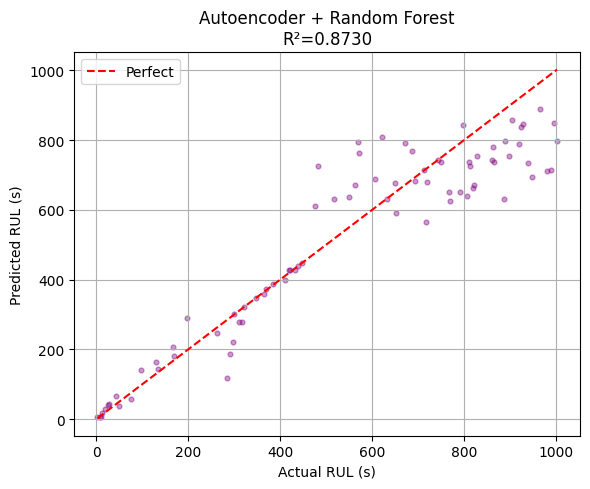

In [77]:
X_latent = encoder.predict(X_all, verbose=0)

Xtr_ae, Xte_ae, _, _ = train_test_split(
    X_latent, RUL_true, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

rf_ae = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=RANDOM_STATE)
rf_ae.fit(Xtr_ae, ytr)
pred_ae = rf_ae.predict(Xte_ae)

evaluate("Autoencoder + Random Forest", yte, pred_ae)
scatter_plot("Autoencoder + Random Forest", yte, pred_ae, color='purple')


## Model 4 — PCA + XGBoost

Gradient-boosted trees on PCA features. Handles nonlinear interactions well.

  PCA + XGBoost                  MAE=   36.55s  RMSE=   53.92s  R²=0.9698


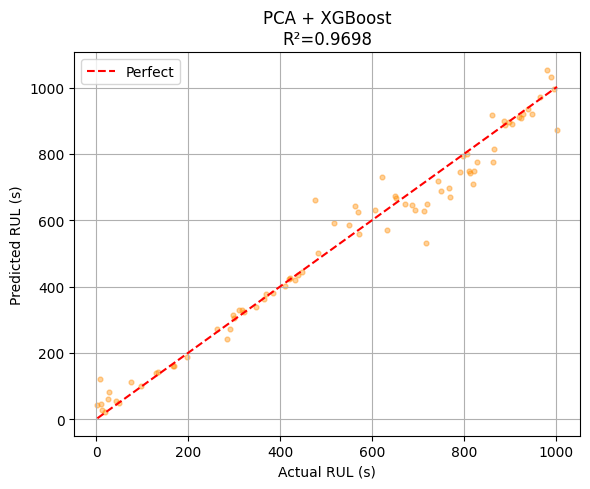

In [78]:
xgb = XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, verbosity=0
)
xgb.fit(Xtr_pca, ytr, eval_set=[(Xte_pca, yte)], verbose=False)
pred_xgb = xgb.predict(Xte_pca)

evaluate("PCA + XGBoost", yte, pred_xgb)
scatter_plot("PCA + XGBoost", yte, pred_xgb, color='darkorange')


## Model 5 — LSTM (Sequence-Based)

Creates overlapping sequences of `SEQ_LEN=20` windows from top features. LSTM learns temporal degradation patterns.

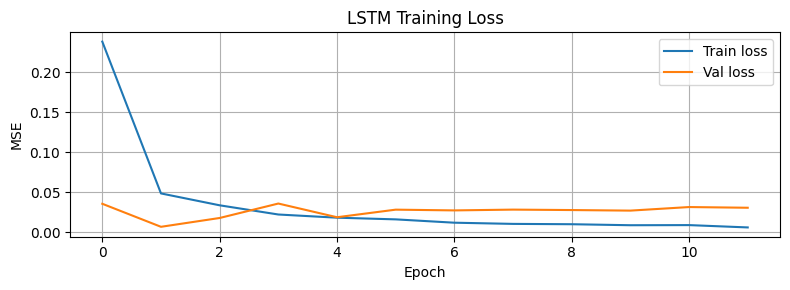

In [79]:
SEQ_LEN = 20

rul_scaler = MinMaxScaler()
y_norm = rul_scaler.fit_transform(RUL_true.reshape(-1,1)).ravel()

sequences, targets = [], []
for i in range(SEQ_LEN, len(X_top)):
    sequences.append(X_top[i-SEQ_LEN:i, :])
    targets.append(y_norm[i])

X_seq = np.array(sequences)
y_seq = np.array(targets)

Xtr_lstm, Xte_lstm, ytr_lstm, yte_lstm = train_test_split(
    X_seq, y_seq, test_size=TEST_SIZE, random_state=RANDOM_STATE, shuffle=False
)

n_feats = X_top.shape[1]
lstm_model = keras.Sequential([
    layers.LSTM(64, return_sequences=True, input_shape=(SEQ_LEN, n_feats)),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='linear')
], name='LSTM_RUL')
lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history_lstm = lstm_model.fit(
    Xtr_lstm, ytr_lstm, epochs=80, batch_size=32,
    validation_split=0.1, callbacks=[early_stop], verbose=0
)

plt.figure(figsize=(8, 3))
plt.plot(history_lstm.history['loss'],     label='Train loss')
plt.plot(history_lstm.history['val_loss'], label='Val loss')
plt.title('LSTM Training Loss'); plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


  LSTM                           MAE=  123.34s  RMSE=  146.76s  R²=-5.9765


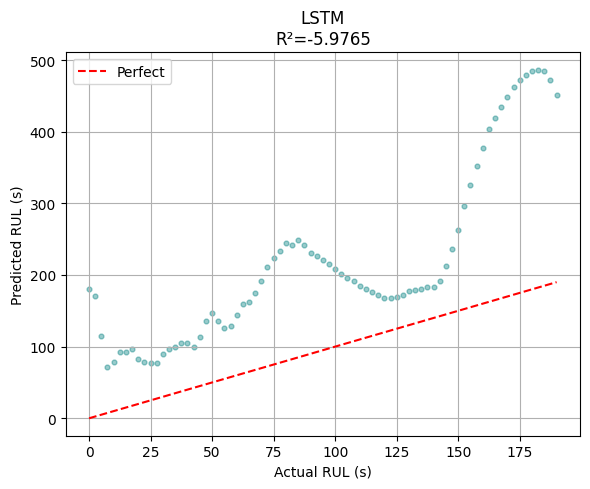

In [80]:
pred_lstm_norm = lstm_model.predict(Xte_lstm, verbose=0).ravel()
pred_lstm  = rul_scaler.inverse_transform(pred_lstm_norm.reshape(-1,1)).ravel()
yte_lstm_s = rul_scaler.inverse_transform(yte_lstm.reshape(-1,1)).ravel()

evaluate("LSTM", yte_lstm_s, pred_lstm)
scatter_plot("LSTM", yte_lstm_s, pred_lstm, color='teal')


## Model 6 — PCA + SVR (Support Vector Regression)

RBF kernel SVR. Maximises margin in PCA space — robust to outliers.

  PCA + SVR                      MAE=  116.36s  RMSE=  146.62s  R²=0.7766


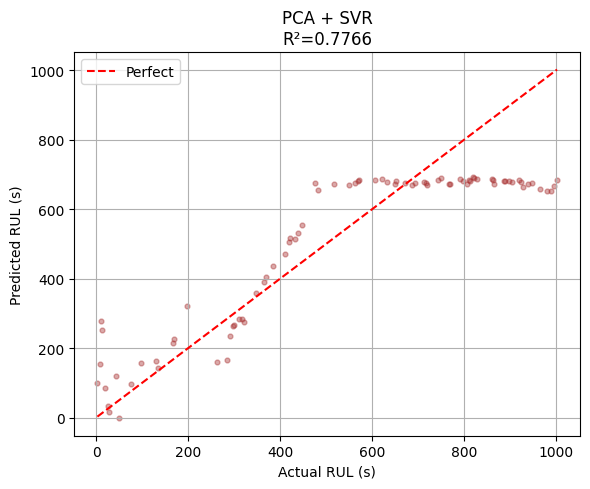

In [81]:
svr = SVR(kernel='rbf', C=1000, epsilon=50, gamma='scale')
svr.fit(Xtr_pca, ytr)
pred_svr = svr.predict(Xte_pca)

evaluate("PCA + SVR", yte, pred_svr)
scatter_plot("PCA + SVR", yte, pred_svr, color='brown')


## Model 7 — PCA + Extra Trees

Extremely Randomised Trees — random split thresholds reduce variance vs RF.

  PCA + Extra Trees              MAE=   40.85s  RMSE=   62.84s  R²=0.9590


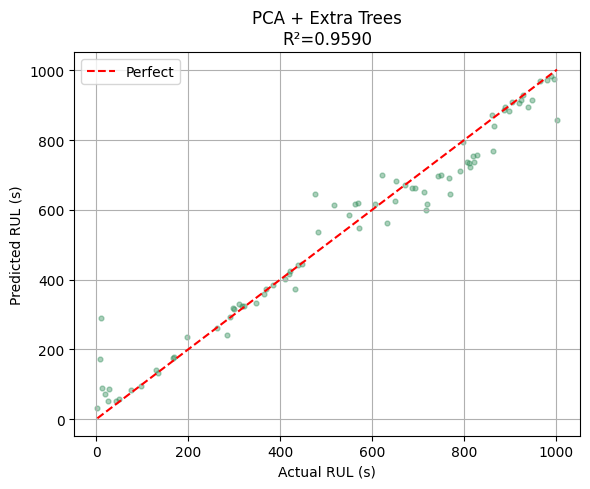

In [82]:
et = ExtraTreesRegressor(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
et.fit(Xtr_pca, ytr)
pred_et = et.predict(Xte_pca)

evaluate("PCA + Extra Trees", yte, pred_et)
scatter_plot("PCA + Extra Trees", yte, pred_et, color='seagreen')


## Model 8 — PCA + Gradient Boosting (sklearn)

Sklearn's GradientBoostingRegressor — sequential tree ensemble with shrinkage.

  PCA + Gradient Boosting        MAE=   27.83s  RMSE=   42.68s  R²=0.9811


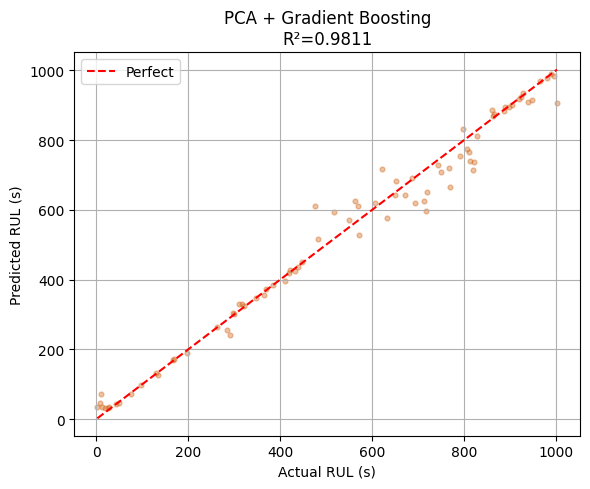

In [83]:
gbr = GradientBoostingRegressor(
    n_estimators=200, max_depth=5, learning_rate=0.05,
    subsample=0.8, random_state=RANDOM_STATE
)
gbr.fit(Xtr_pca, ytr)
pred_gbr = gbr.predict(Xte_pca)

evaluate("PCA + Gradient Boosting", yte, pred_gbr)
scatter_plot("PCA + Gradient Boosting", yte, pred_gbr, color='chocolate')


## Model 9 — PCA + Ridge Regression

L2-regularised linear regression on PCA features. Good interpretability baseline.

  PCA + Ridge Regression         MAE=  111.00s  RMSE=  158.51s  R²=0.7389


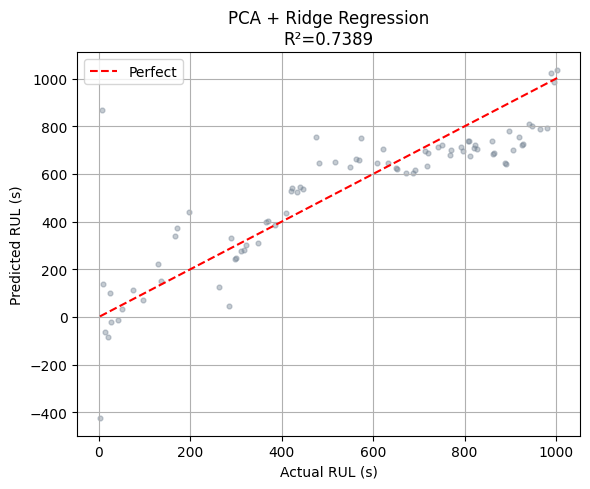

In [84]:
ridge = Ridge(alpha=10.0)
ridge.fit(Xtr_pca, ytr)
pred_ridge = ridge.predict(Xte_pca)

evaluate("PCA + Ridge Regression", yte, pred_ridge)
scatter_plot("PCA + Ridge Regression", yte, pred_ridge, color='slategray')


## Final Model Comparison — R² Table

All 9 models ranked by R² (higher = better). Best model highlighted.

In [85]:
results_df = pd.DataFrame(results).sort_values("R²", ascending=False).reset_index(drop=True)
results_df.index += 1

print("\n" + "="*68)
print("        FINAL MODEL COMPARISON — RUL Prediction (NASA IMS Bearing)")
print("="*68)
print(results_df.to_string())
print("="*68)
print(f"\n  Best Model : {results_df.iloc[0]['Model']}")
print(f"    R²         : {results_df.iloc[0]['R²']}")
print(f"    MAE        : {results_df.iloc[0]['MAE (s)']}s")
print(f"    RMSE       : {results_df.iloc[0]['RMSE (s)']}s")



        FINAL MODEL COMPARISON — RUL Prediction (NASA IMS Bearing)
                         Model  MAE (s)  RMSE (s)      R²
1      PCA + Gradient Boosting    27.83     42.68  0.9811
2          PCA + Random Forest    33.42     49.12  0.9749
3                PCA + XGBoost    36.55     53.92  0.9698
4            PCA + Extra Trees    40.85     62.84  0.9590
5  Autoencoder + Random Forest    79.62    110.57  0.8730
6                    PCA + SVR   116.36    146.62  0.7766
7       PCA + Ridge Regression   111.00    158.51  0.7389
8         KPCA + Random Forest   213.31    257.52  0.3108
9                         LSTM   123.34    146.76 -5.9765

  Best Model : PCA + Gradient Boosting
    R²         : 0.9811
    MAE        : 27.83s
    RMSE       : 42.68s


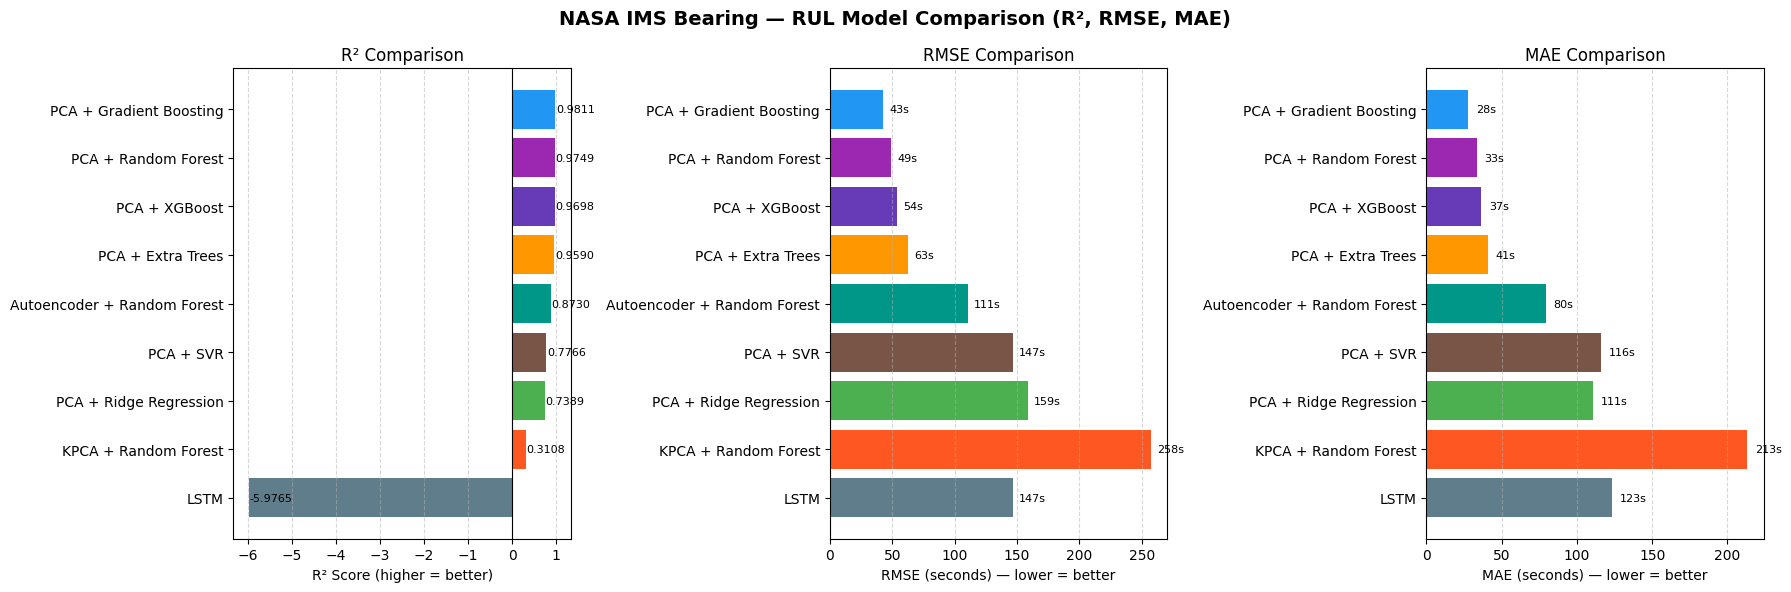

Chart saved → model_comparison.png


In [86]:
# ── Comparison Bar Charts ────────────────────────────────────────────────────
palette = ['#2196F3','#9C27B0','#673AB7','#FF9800','#009688',
           '#795548','#4CAF50','#FF5722','#607D8B']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# R²
bars = axes[0].barh(results_df["Model"], results_df["R²"], color=palette)
axes[0].set_xlabel("R² Score (higher = better)")
axes[0].set_title("R² Comparison")
axes[0].axvline(0, color='black', linewidth=0.8)
for bar, v in zip(bars, results_df["R²"]):
    axes[0].text(bar.get_width()+0.01, bar.get_y()+bar.get_height()/2,
                 f"{v:.4f}", va='center', fontsize=8)
axes[0].invert_yaxis()
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# RMSE
bars2 = axes[1].barh(results_df["Model"], results_df["RMSE (s)"], color=palette)
axes[1].set_xlabel("RMSE (seconds) — lower = better")
axes[1].set_title("RMSE Comparison")
for bar, v in zip(bars2, results_df["RMSE (s)"]):
    axes[1].text(bar.get_width()+5, bar.get_y()+bar.get_height()/2,
                 f"{v:.0f}s", va='center', fontsize=8)
axes[1].invert_yaxis()
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# MAE
bars3 = axes[2].barh(results_df["Model"], results_df["MAE (s)"], color=palette)
axes[2].set_xlabel("MAE (seconds) — lower = better")
axes[2].set_title("MAE Comparison")
for bar, v in zip(bars3, results_df["MAE (s)"]):
    axes[2].text(bar.get_width()+5, bar.get_y()+bar.get_height()/2,
                 f"{v:.0f}s", va='center', fontsize=8)
axes[2].invert_yaxis()
axes[2].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle("NASA IMS Bearing — RUL Model Comparison (R², RMSE, MAE)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved → model_comparison.png")


## Best Model — RUL over Time

Plotting RUL over time for best model: PCA + Gradient Boosting


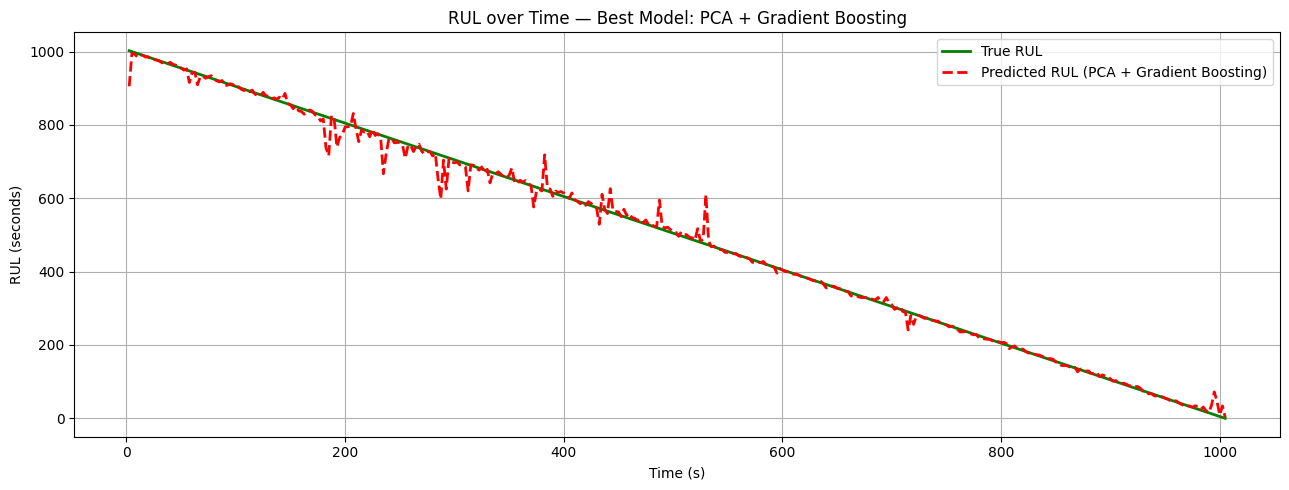

In [87]:
# Identify best model prediction for time-series plot
best_name = results_df.iloc[0]['Model']
print(f"Plotting RUL over time for best model: {best_name}")

# Re-predict on full dataset for time plot
if "Random Forest" in best_name and "Kernel" not in best_name and "Auto" not in best_name:
    best_pred_all = rf.predict(pca.transform(X_all))
elif "XGBoost" in best_name:
    best_pred_all = xgb.predict(pca.transform(X_all))
elif "Extra" in best_name:
    best_pred_all = et.predict(pca.transform(X_all))
elif "Gradient" in best_name:
    best_pred_all = gbr.predict(pca.transform(X_all))
elif "Ridge" in best_name:
    best_pred_all = ridge.predict(pca.transform(X_all))
elif "KPCA" in best_name or "Kernel" in best_name:
    best_pred_all = rf_kpca.predict(kpca.transform(X_all))
elif "Autoencoder" in best_name:
    best_pred_all = rf_ae.predict(encoder.predict(X_all, verbose=0))
elif "SVR" in best_name:
    best_pred_all = svr.predict(pca.transform(X_all))
else:
    lstm_seq = np.array([X_top[i-SEQ_LEN:i,:] for i in range(SEQ_LEN, len(X_top))])
    best_pred_all = rul_scaler.inverse_transform(
        lstm_model.predict(lstm_seq, verbose=0)).ravel()
    time_plot = time_final[SEQ_LEN:]
    rul_plot  = RUL_true[SEQ_LEN:]

if 'time_plot' not in dir():
    time_plot = time_final
    rul_plot  = RUL_true

plt.figure(figsize=(13, 5))
plt.plot(time_plot, rul_plot, color='green', linewidth=2, label='True RUL')
plt.plot(time_plot, best_pred_all[:len(time_plot)], color='red', linewidth=2,
         linestyle='--', label=f'Predicted RUL ({best_name})')
plt.title(f"RUL over Time — Best Model: {best_name}")
plt.xlabel("Time (s)"); plt.ylabel("RUL (seconds)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


## Summary Table

In [88]:
print("\n" + "="*68)
print("  FINAL SUMMARY — Best RUL Regression Model")
print("="*68)
print(results_df.to_string())
print("="*68)

# Save results
results_df.to_csv("model_results.csv", index=False)
print("\nResults saved → model_results.csv")



  FINAL SUMMARY — Best RUL Regression Model
                         Model  MAE (s)  RMSE (s)      R²
1      PCA + Gradient Boosting    27.83     42.68  0.9811
2          PCA + Random Forest    33.42     49.12  0.9749
3                PCA + XGBoost    36.55     53.92  0.9698
4            PCA + Extra Trees    40.85     62.84  0.9590
5  Autoencoder + Random Forest    79.62    110.57  0.8730
6                    PCA + SVR   116.36    146.62  0.7766
7       PCA + Ridge Regression   111.00    158.51  0.7389
8         KPCA + Random Forest   213.31    257.52  0.3108
9                         LSTM   123.34    146.76 -5.9765

Results saved → model_results.csv
